In [44]:
# Data Handling
import pandas as pd
import numpy as np

# Visualization

import matplotlib.pyplot as plt
import seaborn as sns

# machine Learning

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
#from sklearn.file import joblib

In [45]:
df = pd.read_csv("Credit_Card_Defaulter_Prediction.csv")
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000,F,University,Married,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,F,University,Single,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,F,University,Single,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,F,University,Married,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,M,University,Married,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [46]:
df.tail()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
29995,29996,220000,M,High School,Married,39,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29996,29997,150000,M,High School,Single,43,-1,-1,-1,-1,...,8979,5190,0,1837,3526,8998,129,0,0,0
29997,29998,30000,M,University,Single,37,4,3,2,-1,...,20878,20582,19357,0,0,22000,4200,2000,3100,1
29998,29999,80000,M,High School,Married,41,1,-1,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1
29999,30000,50000,M,University,Married,46,0,0,0,0,...,36535,32428,15313,2078,1800,1430,1000,1000,1000,1


In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ID         30000 non-null  int64 
 1   LIMIT_BAL  30000 non-null  int64 
 2   SEX        30000 non-null  object
 3   EDUCATION  30000 non-null  object
 4   MARRIAGE   30000 non-null  object
 5   AGE        30000 non-null  int64 
 6   PAY_0      30000 non-null  int64 
 7   PAY_2      30000 non-null  int64 
 8   PAY_3      30000 non-null  int64 
 9   PAY_4      30000 non-null  int64 
 10  PAY_5      30000 non-null  int64 
 11  PAY_6      30000 non-null  int64 
 12  BILL_AMT1  30000 non-null  int64 
 13  BILL_AMT2  30000 non-null  int64 
 14  BILL_AMT3  30000 non-null  int64 
 15  BILL_AMT4  30000 non-null  int64 
 16  BILL_AMT5  30000 non-null  int64 
 17  BILL_AMT6  30000 non-null  int64 
 18  PAY_AMT1   30000 non-null  int64 
 19  PAY_AMT2   30000 non-null  int64 
 20  PAY_AMT3   30000 non-null  i

In [48]:
df.isnull().sum()

ID           0
LIMIT_BAL    0
SEX          0
EDUCATION    0
MARRIAGE     0
AGE          0
PAY_0        0
PAY_2        0
PAY_3        0
PAY_4        0
PAY_5        0
PAY_6        0
BILL_AMT1    0
BILL_AMT2    0
BILL_AMT3    0
BILL_AMT4    0
BILL_AMT5    0
BILL_AMT6    0
PAY_AMT1     0
PAY_AMT2     0
PAY_AMT3     0
PAY_AMT4     0
PAY_AMT5     0
PAY_AMT6     0
default      0
dtype: int64

In [49]:
df.describe()

,ID,LIMIT_BAL,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,-0.266200,-0.291100,51223.330900,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,9.217904,1.123802,1.197186,1.196868,1.169139,1.133187,1.149988,73635.860576,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-165580.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,3558.750000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,22381.500000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,67091.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,79.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,964511.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [50]:
# How to check for correletion

numeric_df = df.select_dtypes(include=np.number)
correletion = numeric_df.corr()
correletion['default '].sort_values(ascending=False)

default      1.000000
PAY_0        0.324794
PAY_2        0.263551
PAY_3        0.235253
PAY_4        0.216614
PAY_5        0.204149
PAY_6        0.186866
AGE          0.013890
BILL_AMT6   -0.005372
BILL_AMT5   -0.006760
BILL_AMT4   -0.010156
ID          -0.013952
BILL_AMT3   -0.014076
BILL_AMT2   -0.014193
BILL_AMT1   -0.019644
PAY_AMT6    -0.053183
PAY_AMT5    -0.055124
PAY_AMT3    -0.056250
PAY_AMT4    -0.056827
PAY_AMT2    -0.058579
PAY_AMT1    -0.072929
LIMIT_BAL   -0.153520
Name: default , dtype: float64

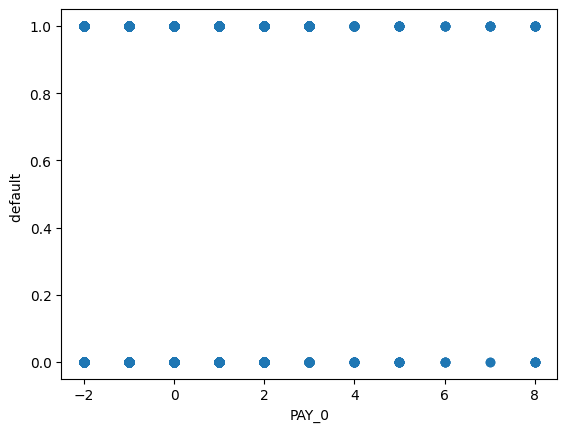

In [51]:
# How to check relationship between dependent varaible (default) and independent varaible (other features)
plt.scatter(df["PAY_0"],df["default "])
plt.xlabel("PAY_0")
plt.ylabel("default ")
plt.show()

In [52]:
df["default "].value_counts()

default 
0    23364
1     6636
Name: count, dtype: int64

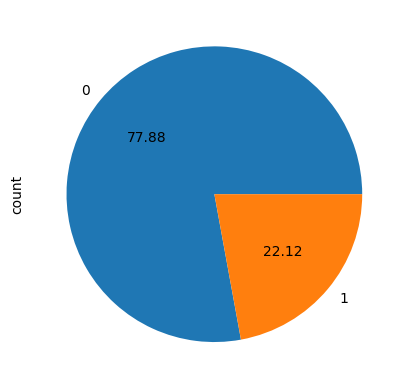

In [53]:
# Using a pie chart
df["default "].value_counts().plot(kind="pie", autopct="%.2f")
plt.show()

<Axes: xlabel='default '>

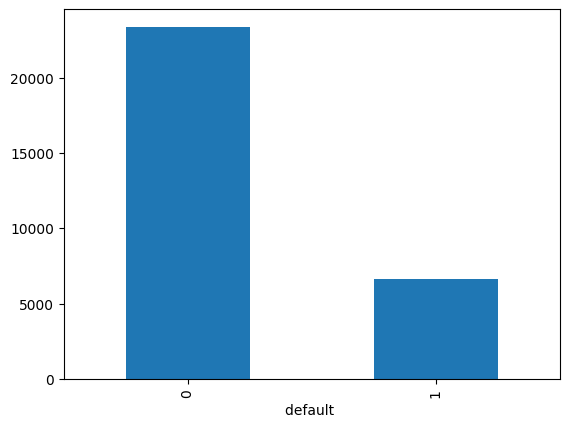

In [54]:
# Using a bar chart
df["default "].value_counts().plot(kind="bar")

In [55]:
df = pd.get_dummies (df, drop_first=True)

In [56]:
X = df.drop(["ID", "default "], axis=1)
y = df["default "]

In [57]:
print(X)

       LIMIT_BAL  AGE  PAY_0  PAY_2  PAY_3  PAY_4  PAY_5  PAY_6  BILL_AMT1  \
0          20000   24      2      2     -1     -1     -2     -2       3913   
1         120000   26     -1      2      0      0      0      2       2682   
2          90000   34      0      0      0      0      0      0      29239   
3          50000   37      0      0      0      0      0      0      46990   
4          50000   57     -1      0     -1      0      0      0       8617   
...          ...  ...    ...    ...    ...    ...    ...    ...        ...   
29995     220000   39      0      0      0      0      0      0     188948   
29996     150000   43     -1     -1     -1     -1      0      0       1683   
29997      30000   37      4      3      2     -1      0      0       3565   
29998      80000   41      1     -1      0      0      0     -1      -1645   
29999      50000   46      0      0      0      0      0      0      47929   

       BILL_AMT2  ...  PAY_AMT6  SEX_M  EDUCATION_Graduate scho

In [58]:
print(y)

0        1
1        1
2        0
3        0
4        0
        ..
29995    0
29996    0
29997    1
29998    1
29999    1
Name: default , Length: 30000, dtype: int64


In [59]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [60]:
scalar = StandardScaler()
X_train = scalar.fit_transform(X_train)
X_test = scalar.transform(X_test)

In [61]:
X_train

array([[-0.67235902, -1.2446578 ,  0.01479575, ..., -0.91539813,
        -0.10586572,  0.93957222],
       [-1.05776818, -0.81152149,  0.01479575, ..., -0.91539813,
        -0.10586572,  0.93957222],
       [ 0.0984593 ,  0.92102376,  0.01479575, ...,  1.09242084,
        -0.10586572, -1.06431414],
       ...,
       [-0.90360452, -1.02808964, -1.76069412, ..., -0.91539813,
        -0.10586572,  0.93957222],
       [-0.74944086, -1.13637372,  0.01479575, ..., -0.91539813,
        -0.10586572,  0.93957222],
       [-0.05570437,  0.05475114, -1.76069412, ...,  1.09242084,
        -0.10586572, -1.06431414]])

In [62]:
X_test

array([[-1.05776818, -1.13637372,  0.01479575, ..., -0.91539813,
        -0.10586572,  0.93957222],
       [-0.1327862 , -1.02808964,  0.01479575, ..., -0.91539813,
        -0.10586572,  0.93957222],
       [-0.74944086, -0.37838517,  0.01479575, ...,  1.09242084,
        -0.10586572, -1.06431414],
       ...,
       [-0.82652269, -0.81152149,  0.01479575, ...,  1.09242084,
        -0.10586572, -1.06431414],
       [-1.13485002, -0.70323741,  0.90254068, ..., -0.91539813,
        -0.10586572,  0.93957222],
       [ 2.64215975,  2.76185308,  0.01479575, ...,  1.09242084,
        -0.10586572, -1.06431414]])

In [63]:
# LogisticRegression
log_model = LogisticRegression()
log_model.fit(X_train, y_train)
y_pred_log = log_model.predict(X_test)
print(accuracy_score(y_test, y_pred_log))
print(confusion_matrix(y_test, y_pred_log))

0.811
[[4551  136]
 [ 998  315]]


In [64]:
# DecisionTreeClassifier
tree_model = DecisionTreeClassifier()
tree_model.fit(X_train, y_train)
y_pred_tree = tree_model.predict(X_test)
print(accuracy_score(y_test, y_pred_tree))
print(confusion_matrix(y_test, y_pred_tree))

0.7278333333333333
[[3812  875]
 [ 758  555]]


In [65]:
# RandomForesClassifier
random_model = RandomForestClassifier()
random_model.fit(X_train, y_train)
y_pred_random = random_model.predict(X_test)
print(accuracy_score(y_test, y_pred_random))
print(confusion_matrix(y_test, y_pred_random))

0.8168333333333333
[[4420  267]
 [ 832  481]]


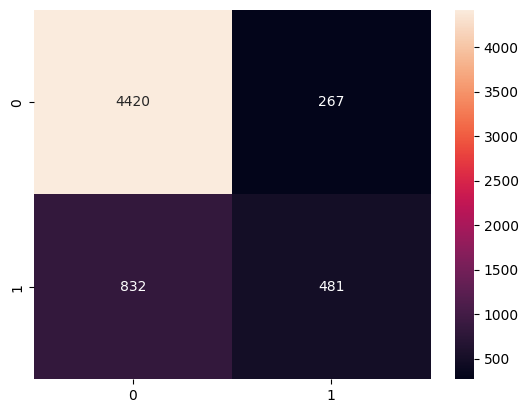

In [66]:
cm = confusion_matrix(y_test, y_pred_random)
sns.heatmap(cm, annot=True, fmt='d')
plt.show()

In [67]:
y_pred_prob = log_model.predict_proba(X_test)[:, 1]
y_pred_prob

array([0.23198469, 0.16007832, 0.21720568, ..., 0.24758728, 0.29500032,
       0.14554964])

In [68]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_log))

              precision    recall  f1-score   support

           0       0.82      0.97      0.89      4687
           1       0.70      0.24      0.36      1313

    accuracy                           0.81      6000
   macro avg       0.76      0.61      0.62      6000
weighted avg       0.79      0.81      0.77      6000



In [69]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_tree))

              precision    recall  f1-score   support

           0       0.83      0.81      0.82      4687
           1       0.39      0.42      0.40      1313

    accuracy                           0.73      6000
   macro avg       0.61      0.62      0.61      6000
weighted avg       0.74      0.73      0.73      6000



In [70]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_random))

              precision    recall  f1-score   support

           0       0.84      0.94      0.89      4687
           1       0.64      0.37      0.47      1313

    accuracy                           0.82      6000
   macro avg       0.74      0.65      0.68      6000
weighted avg       0.80      0.82      0.80      6000



In [71]:
# LogisticRegression and class_weight = "balanced"
log_model_balanced = LogisticRegression(class_weight="balanced")
log_model_balanced.fit(X_train, y_train)
y_pred_log_balanced = log_model_balanced.predict(X_test)
print(accuracy_score(y_test, y_pred_log_balanced))
print(confusion_matrix(y_test, y_pred_log_balanced))
print(classification_report(y_test, y_pred_log_balanced))

0.6913333333333334
[[3295 1392]
 [ 460  853]]
              precision    recall  f1-score   support

           0       0.88      0.70      0.78      4687
           1       0.38      0.65      0.48      1313

    accuracy                           0.69      6000
   macro avg       0.63      0.68      0.63      6000
weighted avg       0.77      0.69      0.71      6000



In [72]:
# DecisionTreeClassifier and class_weight = "balanced"
tree_model_balanced = DecisionTreeClassifier(class_weight="balanced")
tree_model_balanced.fit(X_train, y_train)
y_pred_tree_balanced = tree_model_balanced.predict(X_test)
print(accuracy_score(y_test, y_pred_tree_balanced))
print(confusion_matrix(y_test, y_pred_tree_balanced))
print(classification_report(y_test, y_pred_tree_balanced))

0.7275
[[3865  822]
 [ 813  500]]
              precision    recall  f1-score   support

           0       0.83      0.82      0.83      4687
           1       0.38      0.38      0.38      1313

    accuracy                           0.73      6000
   macro avg       0.60      0.60      0.60      6000
weighted avg       0.73      0.73      0.73      6000



In [73]:
# RandomForestClassifier and class_weight = "balanced"
random_model_balanced = RandomForestClassifier(class_weight="balanced")
random_model_balanced.fit(X_train, y_train)
y_pred_random_balanced = random_model_balanced.predict(X_test)
print(accuracy_score(y_test, y_pred_random_balanced))
print(confusion_matrix(y_test, y_pred_random_balanced))
print(classification_report(y_test, y_pred_random_balanced))

0.8153333333333334
[[4455  232]
 [ 876  437]]
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4687
           1       0.65      0.33      0.44      1313

    accuracy                           0.82      6000
   macro avg       0.74      0.64      0.67      6000
weighted avg       0.80      0.82      0.79      6000



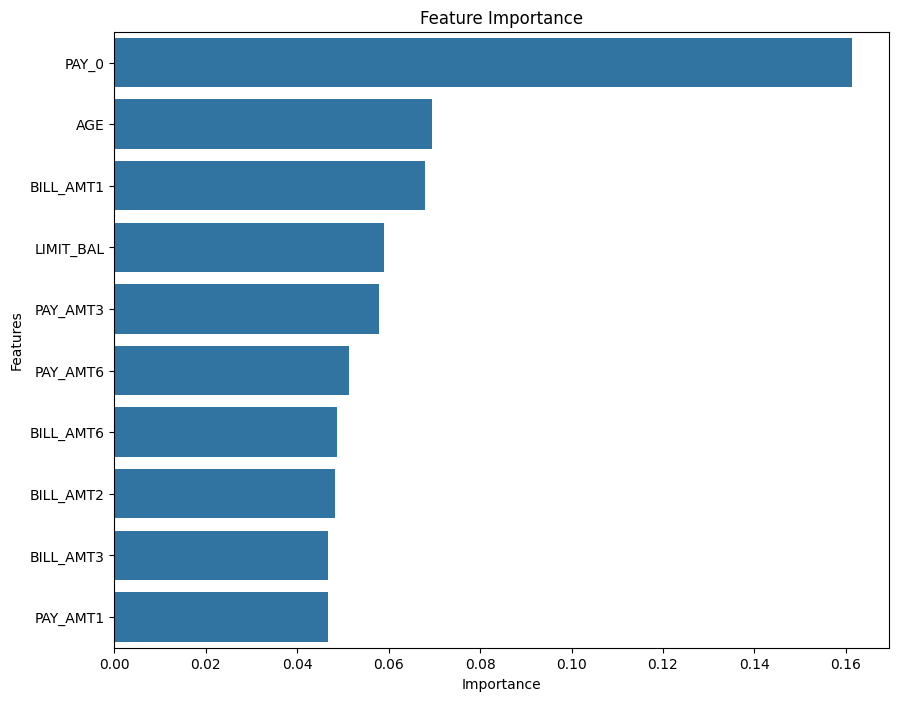

In [74]:
# Get importance from tree model

importances = tree_model.feature_importances_
feature_names = X.columns

# Creates= Dataframe for visualization

feature_importances_df = pd.DataFrame({'Features': feature_names, 'Importance':importances})
feature_importances_df.sort_values('Importance', ascending=False).head(5)

# Plot
plt.figure(figsize=(10,8))
sns.barplot(x='Importance', y='Features', data=feature_importances_df.sort_values('Importance', ascending = False).head(10))
plt.title('Feature Importance')
plt.show()

In [81]:
# Drop PAY_AMT6 and default in a dataset of features

X = df.drop(["default ", "PAY_AMT6"], axis=1)
y = df["default "]

# 2. We Re-split the data

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

# Re-scale the data since X has hew columns now

from sklearn.preprocessing import StandardScaler
scalar = StandardScaler()
X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.transform(X_test)

In [82]:
# Using LogisticRegression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

log_model_balanced = LogisticRegression(max_iter=1000, class_weight="balanced")
log_model_balanced.fit(X_train_scaled, y_train)
y_pred_log_balanced = log_model_balanced.predict(X_test_scaled)

print("---Balanced--LogisticRegression")
print(accuracy_score(y_test, y_pred_log_balanced))
print(confusion_matrix(y_test, y_pred_log_balanced))
print(classification_report(y_test, y_pred_log_balanced))

---Balanced--LogisticRegression
0.6865833333333333
[[6486 2871]
 [ 890 1753]]
              precision    recall  f1-score   support

           0       0.88      0.69      0.78      9357
           1       0.38      0.66      0.48      2643

    accuracy                           0.69     12000
   macro avg       0.63      0.68      0.63     12000
weighted avg       0.77      0.69      0.71     12000



In [88]:
# Using RandomForestClassifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

rmb = RandomForestClassifier(n_estimators=100, class_weight="balanced")
rmb.fit(X_train_scaled, y_train)
y_pred_rmb = rmb.predict(X_test_scaled)

print("---Balanced--RandomForestClassifier")
print(accuracy_score(y_test, y_pred_rmb))
print(confusion_matrix(y_test, y_pred_rmb))
print(classification_report(y_test, y_pred_rmb))

---Balanced--RandomForestClassifier
0.8138333333333333
[[8888  469]
 [1765  878]]
              precision    recall  f1-score   support

           0       0.83      0.95      0.89      9357
           1       0.65      0.33      0.44      2643

    accuracy                           0.81     12000
   macro avg       0.74      0.64      0.66     12000
weighted avg       0.79      0.81      0.79     12000



In [89]:
# Using DecisionTreeClassifier

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

dtc = DecisionTreeClassifier(random_state=42, class_weight="balanced")
dtc.fit(X_train_scaled, y_train)
y_pred_dtc = dtc.predict(X_test_scaled)

print("---Balanced--DecisionTreeClassifier")
print(accuracy_score(y_test, y_pred_dtc))
print(confusion_matrix(y_test, y_pred_dtc))
print(classification_report(y_test, y_pred_dtc))

---Balanced--DecisionTreeClassifier
0.7298333333333333
[[7715 1642]
 [1600 1043]]
              precision    recall  f1-score   support

           0       0.83      0.82      0.83      9357
           1       0.39      0.39      0.39      2643

    accuracy                           0.73     12000
   macro avg       0.61      0.61      0.61     12000
weighted avg       0.73      0.73      0.73     12000



In [90]:
# How to check for cross validation

from sklearn.model_selection import cross_val_score
scores = cross_val_score(rmb, X, y, cv=5)

print(scores.mean())
print(scores.std())

0.8032666666666668
0.018933098590094073


In [91]:
# Get new threshold for the data

y_probs_rf = rmb.predict_proba(X_test_scaled)[:,1]

new_threshold = 0.6
y_pred_tuned = (y_probs_rf >= new_threshold).astype(int)
print(classification_report(y_test, y_pred_tuned))

              precision    recall  f1-score   support

           0       0.82      0.97      0.89      9357
           1       0.70      0.26      0.37      2643

    accuracy                           0.81     12000
   macro avg       0.76      0.61      0.63     12000
weighted avg       0.80      0.81      0.78     12000



In [93]:
# To get Hypertunning

from sklearn.model_selection import  RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': ['balanced', 'balanced_subsample']
}

rf_random = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions = param_dist,
    n_iter=10,
    cv=6,
    scoring="f1",
    verbose=2,
    random_state=42,
    n_jobs=-1
)

rf_random.fit(X_train, y_train)
# to get the best version of our model
best_rf = rf_random.best_estimator_

y_pred_best = best_rf.predict(X_test)
print("--- Best Random Forest Settings ---")
print(rf_random.best_params_)
print("--- Best Random Forest Report ---")
print(classification_report(y_test, y_pred_best))

Fitting 6 folds for each of 10 candidates, totalling 60 fits
--- Best Random Forest Settings ---
{'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 10, 'class_weight': 'balanced_subsample'}
--- Best Random Forest Report ---
              precision    recall  f1-score   support

           0       0.87      0.85      0.86      9357
           1       0.51      0.56      0.53      2643

    accuracy                           0.78     12000
   macro avg       0.69      0.70      0.69     12000
weighted avg       0.79      0.78      0.79     12000



In [95]:
print("--- Best Random Forest Settings ---")
print(rf_random.best_params_)
print("--- Best Random Forest Report ---")
print(classification_report(y_test, y_pred_best))

--- Best Random Forest Settings ---
{'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 10, 'class_weight': 'balanced_subsample'}
--- Best Random Forest Report ---
              precision    recall  f1-score   support

           0       0.87      0.85      0.86      9357
           1       0.51      0.56      0.53      2643

    accuracy                           0.78     12000
   macro avg       0.69      0.70      0.69     12000
weighted avg       0.79      0.78      0.79     12000



C:\Users\Oluwadimimu Adewale\AppData\Local\Temp\ipykernel_20072\3883152451.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y='Features', x='Importances', data=feature_importance_df.sort_values('Importances', ascending=False).head(5), palette='viridis')


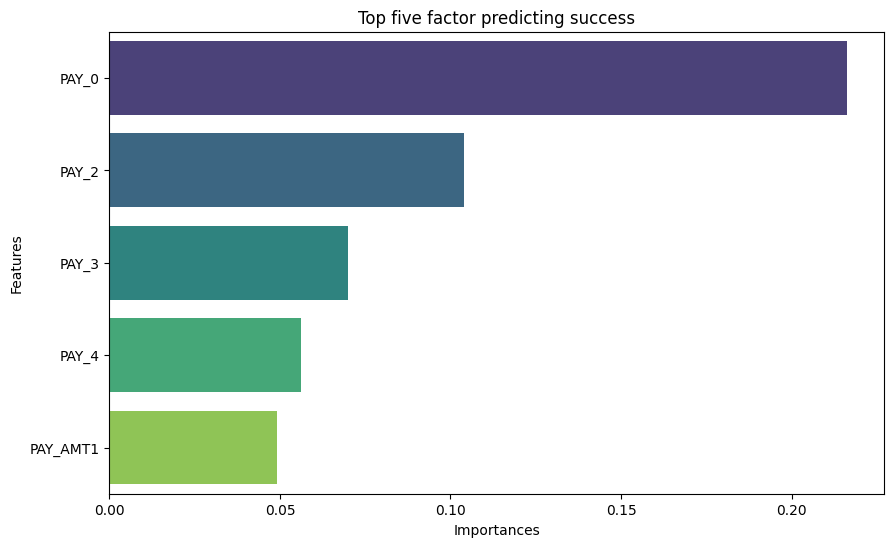

In [99]:
# to get featue importance

importances = best_rf.feature_importances_
feature_names = X.columns

feature_importance_df = pd.DataFrame({'Features': feature_names, 'Importances': importances})
feature_importance_df.sort_values('Importances', ascending= False).head(5)

plt.figure(figsize=(10,6))
sns.barplot(y='Features', x='Importances', data=feature_importance_df.sort_values('Importances', ascending=False).head(5), palette='viridis')
plt.title('Top five factor predicting success')
plt.show()

In [103]:
# let saves the model

import joblib

# to save a trained model to a file

joblib.dump(best_rf, 'best_rf_model.pkl')
joblib.dump(scalar, 'Credit_Card_Defaulter_Prediction_scalar.pkl')

['Credit_Card_Defaulter_Prediction_scalar.pkl']